Steps：
- Data loading and merging
- Data normalization and duplicate removal
- Missing value analysis
- General KPI overview
- Product type revenue and unit analysis

Unfinished:
- Core product filtering
- Valid pricing record definition
- Unit price and margin rate creation
- Monthly pricing history
- Pricing outlier analysis
- Monthly pricing movement
- Product eligibility for price recommendation
- Initial suggested price framework

# Data Loading and Merging

In [17]:
from pathlib import Path
import pandas as pd
import hashlib
from collections import Counter

# Project root directory
project_dir = Path.cwd()

# Raw data folder
raw_data_dir = project_dir / "raw data"

# Automatically collect all quarterly CSV files
files = sorted(raw_data_dir.glob("synthesized_FY*Q*.csv"))

print("Number of files found:", len(files))

Number of files found: 14


In [18]:
# Check file size and row count for each CSV file
file_info = []

for file in files:
    size_mb = file.stat().st_size / 1024 / 1024

    with open(file, "r", encoding="utf-8-sig") as f:
        row_count = sum(1 for _ in f) - 1

    file_info.append(
        {"file_name": file.name, "size_mb": round(size_mb, 2), "row_count": row_count}
    )

file_info_df = pd.DataFrame(file_info)

print("Number of files:", len(files))
print("Total rows:", file_info_df["row_count"].sum())
print("Total size MB:", round(file_info_df["size_mb"].sum(), 2))

Number of files: 14
Total rows: 11738282
Total size MB: 3957.77


In [3]:
# Read a small sample to inspect the data structure
sample = pd.read_csv(files[5], nrows=30)

display(sample.sample(30))

,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,tax,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group
20,2024-07-24,NaN,NaN,2024-07-29,August,FY25Q2,Invoice,Sales Order,DP08113696,GA,...,NaN,0.0,592.0,NaN,FS - Insufficient Inventory,$500 - $699,NaN,Sub-Family Plasma Garnet,Product Family Lantern Orbit,Product Group Lantern Karma
21,2024-07-24,NaN,NaN,2024-07-29,August,FY25Q2,Invoice,Sales Order,DP08113696,GA,...,NaN,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground
5,2024-08-21,NaN,NaN,2024-09-16,September,FY25Q2,Invoice,Credit Memo,DP38967017,BC,...,NaN,0.0,1342.0,NaN,FS - Insufficient Inventory,$1300 - $1499,NaN,Sub-Family Kilo Garnet,Product Family Frame Road,Product Group Peak Flare
11,2024-09-03,NaN,NaN,2024-11-04,November,FY25Q3,Invoice,Sales Order,DP38967017,ON,...,NaN,0.0,622.0,NaN,FS - Insufficient Inventory,$0 - $299,NaN,Sub-Family Grid Century,Product Family Knight Thrive,Product Group Peak Flare
4,2024-09-25,NaN,NaN,2024-12-09,December,FY25Q3,Invoice,Sales Order,DP38967017,BC,...,NaN,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground
18,2024-08-07,NaN,NaN,2024-08-12,August,FY25Q2,Invoice,Sales Order,DP68022333,WA,...,NaN,0.0,35.0,NaN,Others,$0 - $299,NaN,Sub-Family Delta Xray,Product Family Romeo Iris,Product Group Golf Cobalt
25,2024-08-02,NaN,NaN,2024-08-12,August,FY25Q2,Invoice,Credit Memo,DP94238667,FL,...,NaN,0.0,399.0,NaN,FS - Insufficient Inventory,$300 - $499,NaN,Sub-Family Oscar Triumph,Product Family Lantern Orbit,Product Group Lantern Karma
24,2024-08-02,NaN,NaN,2024-08-12,August,FY25Q2,Invoice,Credit Memo,DP94238667,FL,...,NaN,0.0,18.0,NaN,FS - Insufficient Inventory,$0 - $299,NaN,Sub-Family Dawn Rocket,Product Family Juliet Meta,Product Group Road Quest
6,2024-08-21,NaN,NaN,2024-09-16,September,FY25Q2,Invoice,Credit Memo,DP38967017,BC,...,NaN,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground
17,2024-09-02,NaN,NaN,2024-09-02,September,FY25Q2,Invoice,Credit Memo,DP08113696,DE,...,NaN,0.0,172.0,NaN,Order cancelled by customer request,$0 - $299,Chat,Sub-Family Delta Xray,Product Family Romeo Iris,Product Group Golf Cobalt


In [4]:
# Check whether all files have the same columns
columns_by_file = {}

for file in files:
    temp = pd.read_csv(file, nrows=0)
    columns_by_file[file.name] = list(temp.columns)

base_columns = columns_by_file[files[0].name]

for file_name, cols in columns_by_file.items():
    print(file_name, "same columns:", cols == base_columns)

synthesized_FY24Q1.csv same columns: True
synthesized_FY24Q2.csv same columns: True
synthesized_FY24Q3.csv same columns: True
synthesized_FY24Q4.csv same columns: True
synthesized_FY25Q1.csv same columns: True
synthesized_FY25Q2.csv same columns: True
synthesized_FY25Q3.csv same columns: True
synthesized_FY25Q4.csv same columns: True
synthesized_FY26Q1.csv same columns: True
synthesized_FY26Q2.csv same columns: True
synthesized_FY26Q3.csv same columns: True
synthesized_FY26Q4.csv same columns: True
synthesized_FY27Q1.csv same columns: True
synthesized_FY27Q2.csv same columns: True


## Check Cross-Dataset Overlap

In [ ]:
import pandas as pd
import hashlib
from collections import Counter

# Check exact duplicate rows across different files
# This does not load all data into memory at once

seen_rows = {}
cross_file_duplicates = Counter()
cross_file_duplicate_count = 0

for file in files:
    print("Checking:", file.name)

    for chunk in pd.read_csv(file, chunksize=200_000, dtype=str, keep_default_na=False):
        for row in chunk.astype(str).itertuples(index=False, name=None):
            row_text = "\x1f".join(row)
            row_hash = hashlib.blake2b(
                row_text.encode("utf-8"), digest_size=12
            ).hexdigest()

            if row_hash in seen_rows and seen_rows[row_hash] != file.name:
                cross_file_duplicate_count += 1

                pair = tuple(sorted([seen_rows[row_hash], file.name]))
                cross_file_duplicates[pair] += 1
            else:
                seen_rows[row_hash] = file.name

print("Total cross-file duplicate rows:", cross_file_duplicate_count)

print("\nCross-file duplicate pairs:")
for pair, count in cross_file_duplicates.most_common():
    print(pair, count)

Checking: synthesized_FY24Q1.csv
Checking: synthesized_FY24Q2.csv
Checking: synthesized_FY24Q3.csv
Checking: synthesized_FY24Q4.csv
Checking: synthesized_FY25Q1.csv
Checking: synthesized_FY25Q2.csv
Checking: synthesized_FY25Q3.csv
Checking: synthesized_FY25Q4.csv
Checking: synthesized_FY26Q1.csv
Checking: synthesized_FY26Q2.csv
Checking: synthesized_FY26Q3.csv
Checking: synthesized_FY26Q4.csv
Checking: synthesized_FY27Q1.csv
Checking: synthesized_FY27Q2.csv
Total cross-file duplicate rows: 0

Cross-file duplicate pairs:


## Merge All Files

In [ ]:
# Merge all CSV files into one dataframe
dfs = []

for file in files:
    print("Loading:", file.name)

    temp = pd.read_csv(file)

    # Keep track of the original source file
    temp["source_file"] = file.name

    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

print("Merged dataset shape:", df.shape)
display(df.head())

Loading: synthesized_FY24Q1.csv


/var/folders/lm/g5f1tpxn1374_m47thdqzghr0000gn/T/ipykernel_4939/2957100588.py:7: DtypeWarning: Columns (29) have mixed types. Specify dtype option on import or set low_memory=False.
  temp = pd.read_csv(file)


Loading: synthesized_FY24Q2.csv


/var/folders/lm/g5f1tpxn1374_m47thdqzghr0000gn/T/ipykernel_4939/2957100588.py:7: DtypeWarning: Columns (1,2,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  temp = pd.read_csv(file)


Loading: synthesized_FY24Q3.csv


...

/var/folders/lm/g5f1tpxn1374_m47thdqzghr0000gn/T/ipykernel_4939/2957100588.py:7: DtypeWarning: Columns (1,10,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  temp = pd.read_csv(file)


Loading: synthesized_FY27Q2.csv


/var/folders/lm/g5f1tpxn1374_m47thdqzghr0000gn/T/ipykernel_4939/2957100588.py:7: DtypeWarning: Columns (1,28) have mixed types. Specify dtype option on import or set low_memory=False.
  temp = pd.read_csv(file)


Merged dataset shape: (11738282, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


In [ ]:
# Create a normalized copy for duplicate detection and later analysis
df_normalized = df.copy()

# Strip text columns while preserving missing values
text_columns = df_normalized.select_dtypes(include="object").columns

for col in text_columns:
    if col != "source_file":
        df_normalized[col] = df_normalized[col].str.strip()

# Convert date columns
date_columns = ["order_date", "return_date", "ship_date", "week_begin"]

for col in date_columns:
    if col in df_normalized.columns:
        df_normalized[col] = pd.to_datetime(df_normalized[col], errors="coerce")

# Convert numeric columns
numeric_columns = [
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
    "tax",
    "cost",
    "margin",
]

for col in numeric_columns:
    if col in df_normalized.columns:
        df_normalized[col] = pd.to_numeric(df_normalized[col], errors="coerce")

print("Normalized dataset shape:", df_normalized.shape)
display(df_normalized.head())

Normalized dataset shape: (11738282, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaT,NaT,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaT,NaT,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaT,NaT,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


## Data normalization and duplicate removal

In [ ]:
# Check overall exact duplicate rows after merging
duplicate_count = df_normalized.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:", round(duplicate_count / len(df_normalized) * 100, 2), "%"
)

Number of exact duplicate rows: 1358057
Duplicate percentage: 11.57 %


In [ ]:
# View normalized duplicate rows sorted by all columns
normalized_duplicates = df_normalized[df_normalized.duplicated(keep=False)].sort_values(
    list(df_normalized.columns)
)

display(normalized_duplicates.head(50))

,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
494031,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Credit Memo,DP08113696,IL,...,0.01,-0.01,NaN,NaN,$0 - $299,Chat,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
501284,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Credit Memo,DP08113696,IL,...,0.01,-0.01,NaN,NaN,$0 - $299,Chat,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
442749,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Credit Memo,DP08113696,NH,...,0.00,0.00,NaN,NaN,$0 - $299,Chat,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
442750,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Credit Memo,DP08113696,NH,...,0.00,0.00,NaN,NaN,$0 - $299,Chat,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
295055,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.01,-0.01,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
720418,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.01,-0.01,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
174397,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.00,0.00,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
462644,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.00,0.00,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
316321,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.01,-0.01,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
496184,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.01,-0.01,NaN,NaN,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


In [ ]:
from pathlib import Path

# Define columns used for duplicate detection
# Exclude source_file because it is metadata added during loading
duplicate_check_cols = [col for col in df_normalized.columns if col != "source_file"]

# Drop normalized duplicate rows
df_clean = df_normalized.drop_duplicates(
    subset=duplicate_check_cols, keep="first"
).copy()

# Check row counts
print("Original rows:", len(df_normalized))
print("Clean rows:", len(df_clean))
print("Rows removed:", len(df_normalized) - len(df_clean))

# Save clean dataset
output_dir = Path("/Users/AustinZhang/Desktop/Capstone")
output_path = output_dir / "clean_data.csv"

df_clean.to_csv(output_path, index=False)

print("Clean file saved to:", output_path)

Original rows: 11738282
Clean rows: 10380225
Rows removed: 1358057
Clean file saved to: /Users/AustinZhang/Desktop/Capstone/clean_data.csv


# Missing Value Analysis

In [22]:
import pandas as pd
from pathlib import Path

# Load deduplicated data
data_path = Path("/Users/AustinZhang/Desktop/Capstone/Duplicates_Removed_Data.csv")
df_clean = pd.read_csv(data_path)

print("Shape:", df_clean.shape)
display(df_clean.head())

/var/folders/lm/g5f1tpxn1374_m47thdqzghr0000gn/T/ipykernel_4939/2610136642.py:6: DtypeWarning: Columns (0,1,2,3,10,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv(data_path)


Shape: (10380225, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


In [ ]:
# Check missing values
missing_summary = pd.DataFrame(
    {
        "missing_count": df_clean.isna().sum(),
        "missing_percentage": df_clean.isna().mean() * 100,
    }
)

missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_percentage", ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
return_date,10121165,97.504293
reason_of_return,10106206,97.360182
reason_of_cancel,10093210,97.234983
rep_take_role,7881193,75.925069
accessory_category,5037042,48.525364
city,1550598,14.938000
tax,863322,8.316987
ship_date,743637,7.163978
invoice_revenue_country_currency,515826,4.969314
invoice_quantity,515826,4.969314


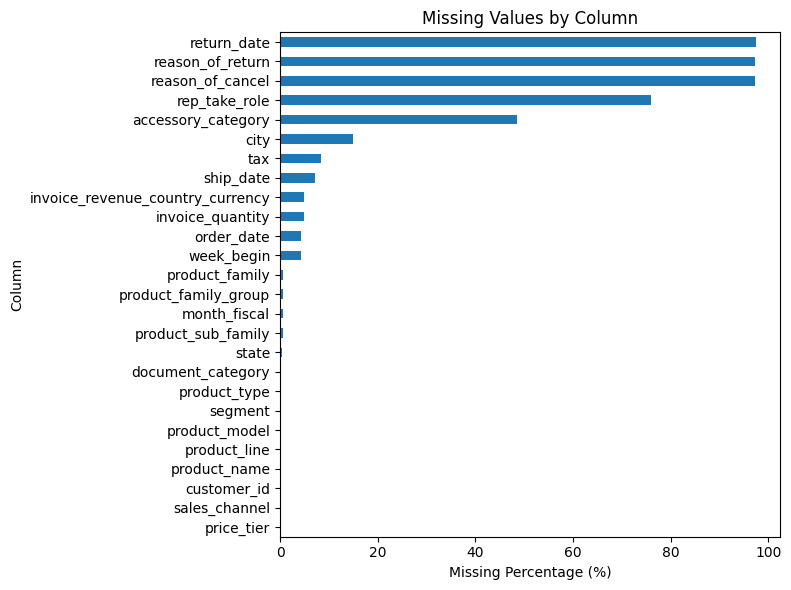

In [ ]:
# Plot missing percentages
import matplotlib.pyplot as plt

missing_summary["missing_percentage"].plot(kind="barh", figsize=(8, 6))

plt.title("Missing Values by Column")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Column")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# KPI Overview

In [25]:
# Convert key columns
date_cols = ["order_date", "return_date", "ship_date", "week_begin"]
numeric_cols = ["order_units", "revenue", "cost", "margin"]

for col in date_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

In [ ]:
# Dataset-level KPIs
dataset_kpis = {
    "rows": len(df_clean),
    "unique_products": df_clean["product_id"].nunique(),
    "unique_customers": df_clean["customer_id"].nunique(),
    "start_date": df_clean["order_date"].min(),
    "end_date": df_clean["order_date"].max(),
}

dataset_kpis_df = pd.DataFrame(dataset_kpis.items(), columns=["KPI", "Value"])

display(dataset_kpis_df)

,KPI,Value
0,rows,10380225
1,unique_products,22296
2,unique_customers,9379
3,start_date,2023-04-01 00:00:00
4,end_date,2026-08-29 00:00:00


In [ ]:
# Define valid sales records
valid_sales_df = df_clean[
    (df_clean["document_type"] == "Invoice")
    & (df_clean["order_status"] == "SHIPS")
    & (df_clean["order_units"] > 0)
    & (df_clean["revenue"] > 0)
].copy()

# Valid-sales KPIs
total_revenue = valid_sales_df["revenue"].sum()
total_units = valid_sales_df["order_units"].sum()
total_cost = valid_sales_df["cost"].sum()
total_margin = valid_sales_df["margin"].sum()

valid_sales_kpis = {
    "valid_sales_rows": len(valid_sales_df),
    "total_revenue": total_revenue,
    "total_units": total_units,
    "total_cost": total_cost,
    "total_margin": total_margin,
    "ASP": total_revenue / total_units,
    "margin_rate": total_margin / total_revenue,
}

valid_sales_kpis_df = pd.DataFrame(valid_sales_kpis.items(), columns=["KPI", "Value"])

display(valid_sales_kpis_df)

,KPI,Value
0,valid_sales_rows,6.527574e+06
1,total_revenue,4.750637e+09
2,total_units,1.021936e+07
3,total_cost,3.821924e+09
4,total_margin,9.286836e+08
5,ASP,4.648665e+02
6,margin_rate,1.954861e-01


## Product type Revenue and Unit Analysis

In [ ]:
# Product type revenue and unit analysis

product_type_summary = (
    valid_sales_df.groupby("product_type", dropna=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("order_units", "sum"),
        transaction_count=("revenue", "count"),
    )
    .reset_index()
)

product_type_summary["ASP"] = (
    product_type_summary["total_revenue"] / product_type_summary["total_units"]
)

product_type_summary["revenue_share"] = (
    product_type_summary["total_revenue"] / product_type_summary["total_revenue"].sum()
)

product_type_summary["unit_share"] = (
    product_type_summary["total_units"] / product_type_summary["total_units"].sum()
)

product_type_summary = product_type_summary.sort_values(
    "total_revenue", ascending=False
)

display(product_type_summary)

,product_type,total_revenue,total_units,transaction_count,ASP,revenue_share,unit_share
3,Notebook,2.698115e+09,2419417.0,1638919,1115.192279,5.679481e-01,2.367484e-01
18,Workstations,9.749525e+08,562448.0,372749,1733.409151,2.052256e-01,5.503751e-02
1,Desktop,3.754051e+08,396495.0,235408,946.809168,7.902206e-02,3.879843e-02
10,Services,2.331197e+08,2748895.0,1776913,84.804881,4.907126e-02,2.689890e-01
4,Options,2.084217e+08,2768783.0,1850606,75.275555,4.387237e-02,2.709351e-01
17,Visuals,1.058621e+08,563513.0,254834,187.860915,2.228376e-02,5.514172e-02
16,Tablets,8.907103e+07,636467.0,281904,139.946036,1.874928e-02,6.228053e-02
9,Servers,4.926780e+07,21012.0,16939,2344.746056,1.037078e-02,2.056098e-03
2,Handheld,1.034545e+07,13651.0,12176,757.852658,2.177697e-03,1.335798e-03
11,Shipping,3.797179e+06,82427.0,82427,46.067177,7.992990e-04,8.065771e-03


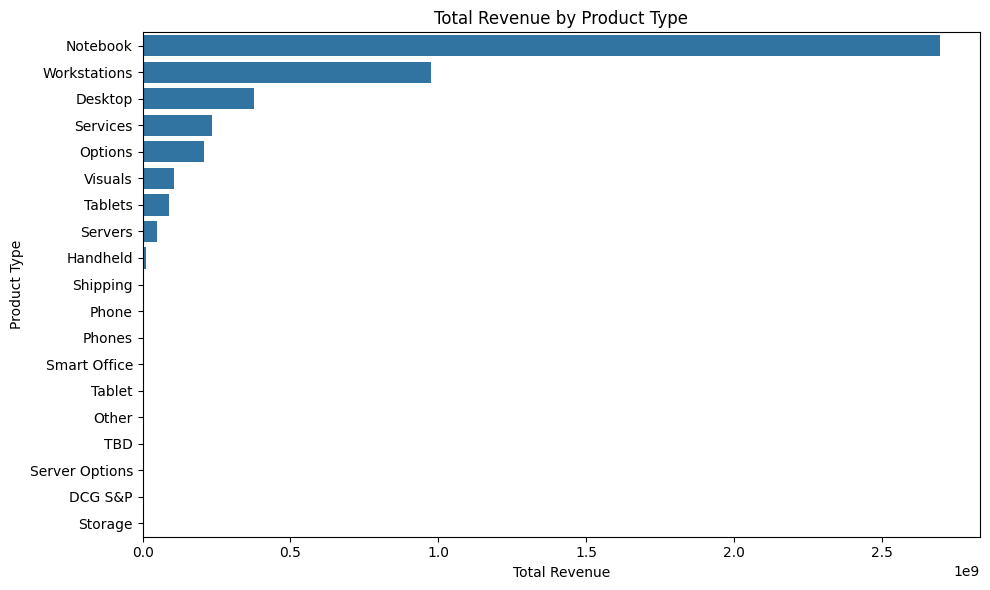

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot total revenue by product type from highest to lowest
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_type_summary.sort_values("total_revenue", ascending=False),
    x="total_revenue",
    y="product_type",
)

plt.title("Total Revenue by Product Type")
plt.xlabel("Total Revenue")
plt.ylabel("Product Type")
plt.tight_layout()
plt.show()

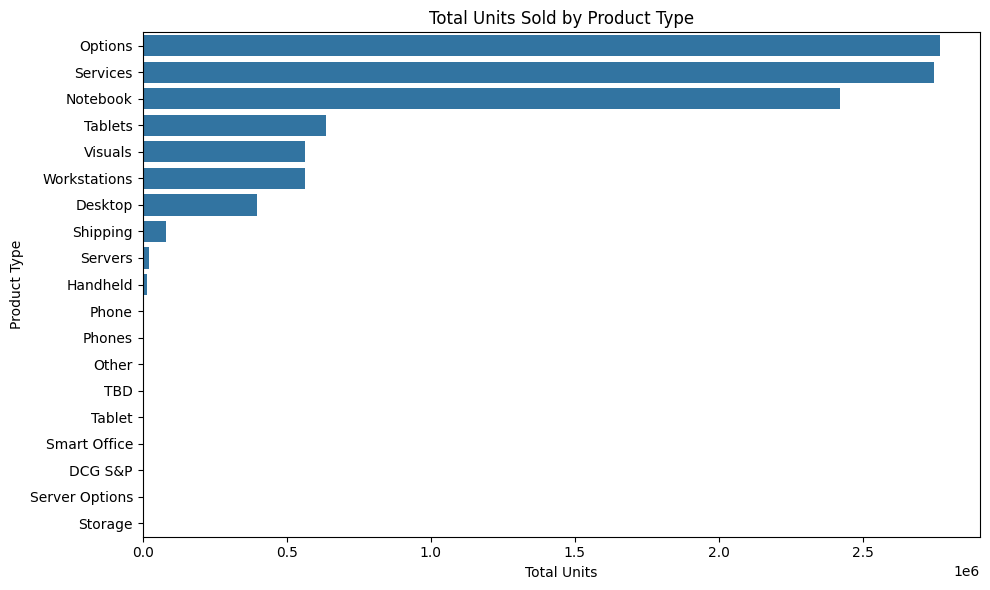

In [ ]:
# Plot total units by product type from highest to lowest
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_type_summary.sort_values("total_units", ascending=False),
    x="total_units",
    y="product_type",
)

plt.title("Total Units Sold by Product Type")
plt.xlabel("Total Units")
plt.ylabel("Product Type")
plt.tight_layout()
plt.show()